<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-063-bellman-from-experience.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 063. Solving Bellman equations with sampled transitions
We use the same three-state decision process as the notes, with the states named $s_{\rm A}$, $s_{\rm B}$ and the terminal $s_{\rm C}$. At $s_{\rm A}$, action $a_1$ moves to $s_{\rm B}$ with probability 0.8 and stays at $s_{\rm A}$ with probability 0.2, with reward zero. Action $a_2$ ends the episode with reward -1. At $s_{\rm B}$, its only action terminates with reward 10 with probability 0.9 and returns to $s_{\rm A}$ with reward zero with probability 0.1. State $s_{\rm C}$ is terminal. The discount is 0.9.

The model is known to us so that we can compute a reference. The learner uses only sampled transitions. We show that the mean sampled target is the Bellman right-hand side, that the mean TD error is its residual, and that learning moves estimates towards that consistency condition. Run the cells in order with NumPy and Matplotlib. The core route ends after the single-entry update. The final learning-curve section is optional and takes most of the runtime.

In [1]:
from pathlib import Path
import json,time
import numpy as np
import matplotlib.pyplot as plt
OUT=Path('classroom_results');OUT.mkdir(exist_ok=True)
FIG=Path('figures');FIG.mkdir(exist_ok=True)
started=time.perf_counter();gamma=.9
# Python indices 0,1,2 represent lecture states sA,sB,sC.
allowed={0:[0,1],1:[0],2:[]}
model={(0,0):[(.8,1,0.),(.2,0,0.)],(0,1):[(1.,2,-1.)],
       (1,0):[(.9,2,10.),(.1,0,0.)]}
def step(s,a,rng):
    outcomes=model[s,a];i=rng.choice(len(outcomes),p=[x[0] for x in outcomes])
    _,sn,r=outcomes[i]
    return sn,r,sn==2
P=np.array([[.2,.8],[.1,0.]])
reward=np.array([0.,9.])
Vpi=np.linalg.solve(np.eye(2)-gamma*P,reward)
def bellman_q(Q):
    new=np.zeros_like(Q)
    for (s,a),outcomes in model.items():
        new[s,a]=sum(prob*(r+(gamma*max(Q[sn,j] for j in allowed[sn]) if sn!=2 else 0.)) for prob,sn,r in outcomes)
    return new
Qstar=np.zeros((3,2))
for _ in range(1000):Qstar=bellman_q(Qstar)
assert np.allclose(Qstar[:2,0],Vpi)
print('Policy a1 values, from exact linear equations:',Vpi)
print('Optimal Q table; unused entries are marked with a dash')
for s in [0,1]:print('s'+'AB'[s],[round(float(Qstar[s,a]),5) if a in allowed[s] else '-' for a in range(2)])


Policy a1 values, from exact linear equations: [8.58050847 9.77224576]
Optimal Q table; unused entries are marked with a dash
sA [8.58051, -1.0]
sB [9.77225, '-']


## A Bellman target is an average
Freeze a current table. For the single action at $s_{\rm B}$, a transition supplies target 10 or $0.9\max_aQ(s_{\rm A},a)$. The model average is their probability-weighted mean. TD subtracts the current $Q(s_{\rm B},a_1)$ from that target. We can compare the sampled mean error with the exact Bellman residual without performing any learning.

Possible targets [10.  0.] with probabilities [0.9 0.1]
Mean target 9.0 current estimate 3.0 mean TD error 6.0
Sampled mean target 8.987
TD errors at the exact solution [ 0.22775424 -2.04978814] ; their mean -6.386546188319088e-16


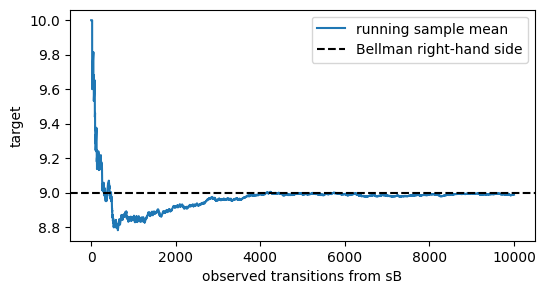

In [2]:
Q=np.zeros((3,2));Q[1,0]=3.
targets=np.array([10.,gamma*Q[0].max()]);prob=np.array([.9,.1])
expected_target=prob@targets
expected_error=prob@(targets-Q[1,0])
residual=bellman_q(Q)[1,0]-Q[1,0]
assert np.isclose(expected_error,residual)
print('Possible targets',targets,'with probabilities',prob)
print('Mean target',expected_target,'current estimate',Q[1,0],'mean TD error',expected_error)
rng=np.random.default_rng(630)
samples=rng.choice(targets,size=10000,p=prob)
means=np.cumsum(samples)/np.arange(1,len(samples)+1)
print('Sampled mean target',means[-1])
fig,ax=plt.subplots(figsize=(6,3));ax.plot(means,label='running sample mean')
ax.axhline(expected_target,color='black',ls='--',label='Bellman right-hand side')
ax.set_xlabel('observed transitions from sB');ax.set_ylabel('target');ax.legend();plt.show()
# Even at the exact solution, individual errors need not be zero.
true_targets=np.array([10.,gamma*Qstar[0].max()])
true_errors=true_targets-Qstar[1,0]
assert np.isclose(prob@true_errors,0,atol=1e-10)
print('TD errors at the exact solution',true_errors,'; their mean',prob@true_errors)


## One visited entry changes
The update moves one entry a fraction $\alpha$ towards its observed target. For a terminal observation with reward 10, the continuation is zero. The sampled target is 10 even though the average target at the frozen table above is 9. The difference is sampling noise. The Bellman equation constrains only the average target. The second column at $s_{\rm B}$ belongs to $a_2$, which is unavailable at $s_{\rm B}$, so that entry is never updated and stays at zero.

In [3]:
before=Q.copy();alpha=.2;sampled_target=10.
Q[1,0]+=alpha*(sampled_target-Q[1,0])
print('Current row at sB before update:',before[1])
print('Current row at sB after update :',Q[1])
print('Expected new entry at this frozen table:',before[1,0]+alpha*expected_error)
assert np.isclose(Q[1,0],4.4)


Current row at sB before update: [3. 0.]
Current row at sB after update : [4.4 0. ]
Expected new entry at this frozen table: 4.2


The core route ends here. Before continuing, explain why the sampled target 10 differs from the mean target 9 and why the mean TD error vanishes at the exact solution although individual TD errors do not.

## Optional learning from repeated experience
For value prediction, we always take $a_1$ and perform TD updates on a value table. For control, an exploratory behaviour policy samples actions while each Q-learning target uses the greedy maximum. Learning rates decrease by the number of visits to each entry. The code below never calls `bellman_q` inside its learning update. That function is used only to evaluate the residual against a known reference.

Learning curves can fluctuate and a single transition can increase error. The convergence theorem concerns repeated sampling under coverage and step-size conditions.

seed 0 Q(sB,a1) 9.7413 V(sA), V(sB) [8.5693 9.7672] max V error 0.0113 final Q error 0.0309 Bellman residual 0.0305
seed 1 Q(sB,a1) 9.8172 V(sA), V(sB) [8.5862 9.8247] max V error 0.0524 final Q error 0.0449 Bellman residual 0.042
seed 2 Q(sB,a1) 9.7744 V(sA), V(sB) [8.6007 9.7998] max V error 0.0275 final Q error 0.0189 Bellman residual 0.0139
seed 3 Q(sB,a1) 9.7419 V(sA), V(sB) [8.5825 9.7696] max V error 0.0026 final Q error 0.0303 Bellman residual 0.0363
exact V(sA), V(sB) for always taking a1: [8.5805 9.7722]


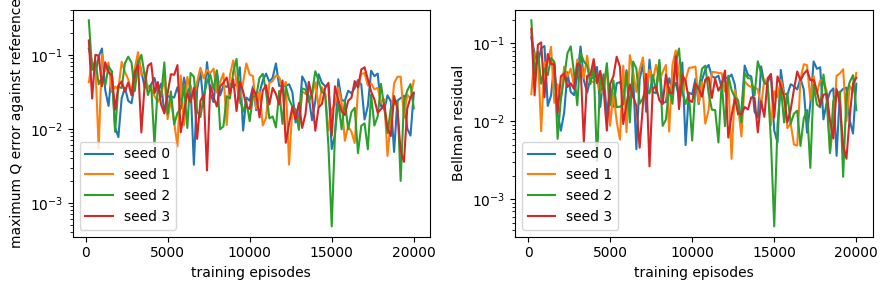

In [4]:
def learn(seed,episodes=20000):
    rng=np.random.default_rng(seed);Q=np.zeros((3,2));visits=np.zeros_like(Q)
    V=np.zeros(3);vvisits=np.zeros(3);logs=[]
    for episode in range(episodes):
        s=0
        while s!=2:
            a=0;sn,r,done=step(s,a,rng)
            vvisits[s]+=1;alpha=vvisits[s]**(-.6)
            V[s]+=alpha*(r+(0 if done else gamma*V[sn])-V[s]);s=sn
        s=0
        while s!=2:
            choices=allowed[s]
            a=int(rng.choice(choices)) if rng.random()<.2 else max(choices,key=lambda j:Q[s,j])
            sn,r,done=step(s,a,rng)
            y=r if done else r+gamma*max(Q[sn,j] for j in allowed[sn])
            visits[s,a]+=1;alpha=visits[s,a]**(-.6)
            Q[s,a]+=alpha*(y-Q[s,a]);s=sn
        if (episode+1)%200==0:
            mask=np.array([[True,True],[True,False],[False,False]])
            residual=np.max(np.abs((bellman_q(Q)-Q)[mask]))
            logs.append((episode+1,np.max(abs(Q-Qstar)),residual,np.max(abs(V[:2]-Vpi))))
    return Q,V,np.array(logs)
runs=[learn(seed) for seed in range(4)]
fig,axes=plt.subplots(1,2,figsize=(9,3))
for seed,(Q,V,log) in enumerate(runs):
    axes[0].plot(log[:,0],log[:,1],label=f'seed {seed}')
    axes[1].plot(log[:,0],log[:,2],label=f'seed {seed}')
    print('seed',seed,'Q(sB,a1)',round(float(Q[1,0]),4),'V(sA), V(sB)',np.round(V[:2],4),'max V error',round(float(log[-1,3]),4),
          'final Q error',round(float(log[-1,1]),4),'Bellman residual',round(float(log[-1,2]),4))
print('exact V(sA), V(sB) for always taking a1:',np.round(Vpi,4))
axes[0].set_ylabel('maximum Q error against reference');axes[1].set_ylabel('Bellman residual')
for ax in axes:ax.set_xlabel('training episodes');ax.legend();ax.set_yscale('log')
fig.tight_layout()
for ext in ['pdf','png']:fig.savefig(FIG/('fig_bellman_sampling.'+ext),bbox_inches='tight',dpi=160)
plt.show()
summary={'environment':'lecture three-state process','discount':gamma,'true_policy_values':Vpi.tolist(),
         'true_Q':Qstar.tolist(),'seeds':list(range(4)),
         'final_Q':[Q.tolist() for Q,V,log in runs],
         'final_error':[float(log[-1,1]) for Q,V,log in runs],
         'final_V':[V[:2].tolist() for Q,V,log in runs],'final_V_error':[float(log[-1,3]) for Q,V,log in runs],
         'runtime_seconds':time.perf_counter()-started}
(OUT/'lab063_results.json').write_text(json.dumps(summary,indent=2))


After 20,000 episodes the four seeds end with maximum Q errors between 0.019 and 0.045 and Bellman residuals between 0.014 and 0.042. The TD(0) value prediction for the policy that always takes $a_1$ gives $V(s_{\rm B})$ between 9.767 and 9.825 against the exact 9.772, with maximum value errors between 0.003 and 0.052. The errors keep fluctuating because the step sizes $n^{-0.6}$ decrease slowly and each update uses one sampled outcome. Learning reduces the residual without making it exactly zero in a finite run.

## The relation to a quantum compiler
The same target calculation applies when the state is a prepared quantum state and the action is a gate. The reward can be fidelity gain minus gate cost. For a finite gate budget, the remaining budget belongs in the state, and exhaustion has zero continuation. Lab 058 supplies that implementation. A neural Q-network uses regression on sampled Bellman targets, but the tabular contraction and convergence proof do not automatically carry over to the network.

Derive the conditional expected Q-learning update and identify where the environment average is replaced by a sample. Explain why changing the exploratory behaviour does not insert that policy's probabilities into the greedy Q-learning target.